# 09 — Frequencies, masks and batch processing

**Goal:** (1) compare frequency A (20 MHz) and frequency B (5 MHz) on the same AOI; (2) process
every discovered covariance term of every frequency in one loop, with the validity mask applied,
and export them as GeoTIFF — nothing hard-coded.

In [1]:
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from nisar_s1.config import load_kit
from nisar_s1 import product as P

kit = load_kit()                                  # notebooks/kit_config.yaml
OUT = Path(kit["data_dir"]) / "outputs" / "09"   # outputs stay outside the repository
OUT.mkdir(parents=True, exist_ok=True)
plt.rcParams.update({"figure.dpi": 90, "axes.spines.top": False, "axes.spines.right": False})
session = P.load_session(kit["session_file"], required=("granule", "aoi_bounds"))
src_ctx = lambda: P.open_local_or_remote(session["gcov_local"], session["gcov_url"])
from nisar_s1.polarimetry import to_db
from nisar_s1.optical import Raster, save_raster

In [2]:
with src_ctx() as h5:
    prof = P.product_profile(h5)
    data = {}
    for f, gr in prof.grids.items():
        w = P.window_from_bounds(gr, session["aoi_bounds"])
        m = P.read_layer(h5, gr, "mask", w, nodata_zero=False)
        data[f] = {"grid": gr, "win": w, "valid": (m != 0) & (m != 255),
                   **{t: P.read_layer(h5, gr, t, w) for t in gr.terms}}
pd.DataFrame([{"frequency": f, "pixel (m)": d["grid"].dx, "AOI pixels": d["win"].shape,
               **{f"{t} median (dB)": round(float(np.nanmedian(to_db(d[t]))), 2) for t in d["grid"].terms}}
              for f, d in data.items()])

opening local file: NISAR_L2_PR_GCOV_034_144_A_026_2005_DHDH_M_20261103T041937_20261103T042013_P05036_N_F_J_001.h5


,frequency,pixel (m),AOI pixels,HHHH median (dB),HVHV median (dB)
0,frequencyA,20.0,"(288, 312)",-5.57,-10.62
1,frequencyB,80.0,"(73, 79)",-5.01,-10.11


The 5 MHz grid is 4 x coarser. Medians agree (same radar, same calibration), but a clear-cut of
2.4 ha covers ~60 pixels at 20 m and only ~4 at 80 m: frequency B is not usable for small cuts.

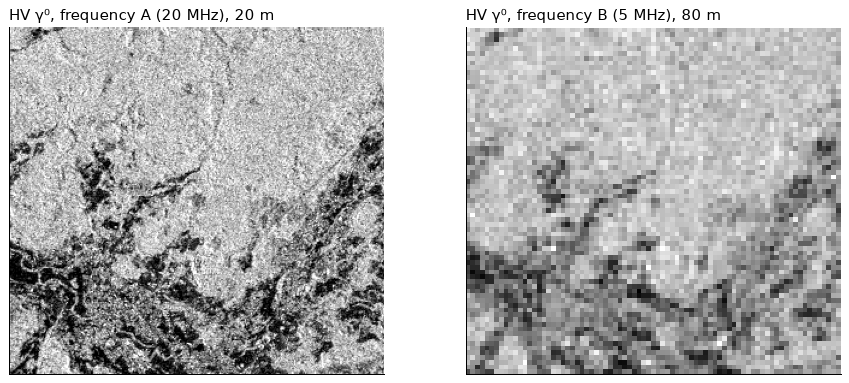

pixel ratio B/A: 4


In [3]:
A, B = data["frequencyA"], data["frequencyB"]
k = int(round(B["grid"].dx / A["grid"].dx))
fig, axs = plt.subplots(1, 2, figsize=(12, 5))
for ax, (d, t) in zip(axs, [(A, "frequency A (20 MHz)"), (B, "frequency B (5 MHz)")]):
    lo, hi = np.nanpercentile(to_db(A["HVHV"]), [2, 98])         # same stretch for both grids
    ax.imshow(to_db(d["HVHV"]), cmap="gray", vmin=lo, vmax=hi)
    ax.set_title(f"HV γ⁰, {t}, {d['grid'].dx:.0f} m", loc="left"); ax.set_xticks([]); ax.set_yticks([])
plt.show()
print("pixel ratio B/A:", k)

## Batch: every term x every frequency, masked, to GeoTIFF

In [4]:
written = []
jobs = [(f, t) for f, d in data.items() for t in d["grid"].terms]
for i, (f, t) in enumerate(jobs, 1):
    d = data[f]
    arr = to_db(np.where(d["valid"], d[t], np.nan))
    path = OUT / f"{session['granule'][:60]}_{f}_{t}_dB.tif"
    save_raster(Raster(arr, d["win"].transform, d["win"].crs), path)
    written.append(path)
    print(f"[{i}/{len(jobs)}] {path.name}")

[1/4] NISAR_L2_PR_GCOV_034_144_A_026_2005_DHDH_M_20261103T041937_2_frequencyA_HHHH_dB.tif
[2/4] NISAR_L2_PR_GCOV_034_144_A_026_2005_DHDH_M_20261103T041937_2_frequencyA_HVHV_dB.tif
[3/4] NISAR_L2_PR_GCOV_034_144_A_026_2005_DHDH_M_20261103T041937_2_frequencyB_HHHH_dB.tif
[4/4] NISAR_L2_PR_GCOV_034_144_A_026_2005_DHDH_M_20261103T041937_2_frequencyB_HVHV_dB.tif


In [5]:
checks = {
    "two frequencies processed": len(data) == 2,
    "4 GeoTIFF written": len(written) == 4 and all(p.exists() for p in written),
    "B is 4x coarser": k == 4,
}
for k, v in checks.items():
    print(f"  [{'x' if v else ' '}] {k}")
assert all(checks.values()), "some checks failed: read the messages above"
print("Module 09 STATUS: PASS")

  [x] two frequencies processed
  [x] 4 GeoTIFF written
  [x] B is 4x coarser
Module 09 STATUS: PASS
